[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Visualización efectiva.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo II: *Describir y comparar*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se elegirá la gráfica adecuada para cada pregunta y se aplicarán reglas prácticas de visualización con *Matplotlib* y *Seaborn*.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* **Ejercicio básico:** lo que todos deben dominar.
* **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

La API que se usa hoy está explicada método por método en py311; aquí solo se repasa y el tiempo se dedica a **interpretar** y a **decidir** qué tabla, qué medida de asociación y qué gráfica responden mejor la pregunta:

| Tema | *Notebooks* de py311 |
|---|---|
| `melt`, `stack`/`unstack`, `pivot_table`, `crosstab` | [21 Transformación de *dataframes* y series](https://github.com/PythonistaMX/py311/blob/main/21_transformacion_de_objetos.ipynb) |
| `groupby`, agregación y `transform` por grupo | [24 Métodos `groupby()`](https://github.com/PythonistaMX/py311/blob/main/24_metodos_groupby.ipynb) |
| *Seaborn*: funciones por tipo de gráfica y la interfaz de objetos | [31 Introducción a *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb) · [32 Objetos de *Seaborn*](https://github.com/PythonistaMX/py311/blob/main/32_objetos_de_seaborn.ipynb) |

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3, así que pueden verse diferencias (por ejemplo, texto como `object` en lugar de `str`, o el uso de `inplace=True`). Cuando difieran, se sigue lo que muestra este *notebook* (ver la sección 1.1 de `03_pandas_3_esencial.ipynb`).

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluido el módulo `stats` de *SciPy*, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats

warnings.filterwarnings("ignore", message="vert: bool was deprecated")

**Nota:** el filtro de advertencias oculta solo un aviso interno de *Seaborn* 0.13 con *Matplotlib* 3.11 al dibujar diagramas de caja (`vert: bool was deprecated`). No afecta los resultados.

* La siguiente celda leerá `penguins_limpio.csv` o lo regenerará desde `penguins.csv` si no existe.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio).astype({"species": "category", "island": "category", "sex": "category"})
pinguinos.shape

(342, 7)

`tips` registra 244 cuentas de un restaurante: `total_bill` (cuenta, en dólares), `tip` (propina), `sex` y `smoker` de quien paga, `day`, `time` (comida o cena) y `size` (personas en la mesa). Se creará la **propina porcentual** `tip_pct = 100 · tip / total_bill` y se ordenarán los días.

* La siguiente celda leerá `tips.csv`, creará `tip_pct` y convertirá `day` y `time` en categorías ordenadas.

In [3]:
propinas = (
    pd.read_csv(os.path.join(DATA, "tips.csv"))
    .assign(tip_pct=lambda d: 100 * d["tip"] / d["total_bill"])
    .astype({"day": pd.CategoricalDtype(["Thur", "Fri", "Sat", "Sun"], ordered=True),
             "time": pd.CategoricalDtype(["Lunch", "Dinner"], ordered=True)})
)
propinas.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


---
## 1. Visualización efectiva.

### 1.1 Elegir la gráfica según la pregunta.

| Pregunta | Gráficas recomendadas | Evitar |
|---|---|---|
| ¿Cómo se distribuye una variable? | Histograma, KDE, ECDF | Pastel |
| ¿Cómo se compara una numérica entre grupos? | Diagrama de caja, violín, puntos con intervalo, *strip plot* | Barras de medias sin dispersión |
| ¿Cómo se relacionan dos numéricas? | Dispersión (con color por grupo, recta o suavizado) | Líneas que unan puntos no ordenados |
| ¿Cómo se reparte un total? | Barras (apiladas o al 100%) | Pastel con muchas categorías, 3D |
| ¿Cómo cambia en el tiempo? | Líneas | Barras con muchas fechas |

### 1.2 Reglas prácticas.

* **Escalas:** las barras empiezan en cero; para datos multiplicativos, escala logarítmica.
* **Facetas** (`col=`, `row=`) en lugar de amontonar muchos grupos en un solo panel.
* **Color** con significado: una paleta cualitativa para categorías, secuencial para cantidades y divergente para valores alrededor de un centro. Mantener el mismo color para el mismo grupo en todas las gráficas y preferir paletas aptas para daltonismo.
* **Rótulos:** ejes con unidades y un **título que diga el hallazgo**, no solo las variables.
* **Anotaciones** para señalar lo importante.

**¿Por qué importa?** Una gráfica es, muchas veces, lo único que el lector recuerda de un análisis. Una gráfica mal elegida puede ocultar lo importante (un diagrama de caja oculta dos picos) o exagerar diferencias (un eje que no empieza en cero). Las tablas siguientes resumen qué gráfica responde cada pregunta y qué reglas evitan los errores más comunes.

### 1.3 *Matplotlib* vs. *Seaborn*.

[*Seaborn*](https://seaborn.pydata.org) produce gráficas estadísticas con poco código a partir de un *dataframe* en formato largo (agrupa, colorea, faceta y calcula intervalos). [*Matplotlib*](https://matplotlib.org) da control total de cada elemento. En la práctica se combinan: las funciones de *Seaborn* devuelven un objeto `Axes` de *Matplotlib* que se puede seguir ajustando. Las familias de funciones de *Seaborn* (relacionales, categóricas, de distribución y matriciales) y su interfaz de objetos (`seaborn.objects`) se repasan en [py311 · 31](https://github.com/PythonistaMX/py311/blob/main/31_introduccion_a_seaborn.ipynb) y [py311 · 32](https://github.com/PythonistaMX/py311/blob/main/32_objetos_de_seaborn.ipynb).

**Ejemplo:** la misma información (masa media por especie) en una gráfica engañosa y en una gráfica efectiva.

* La siguiente celda dibujará ambas versiones lado a lado.

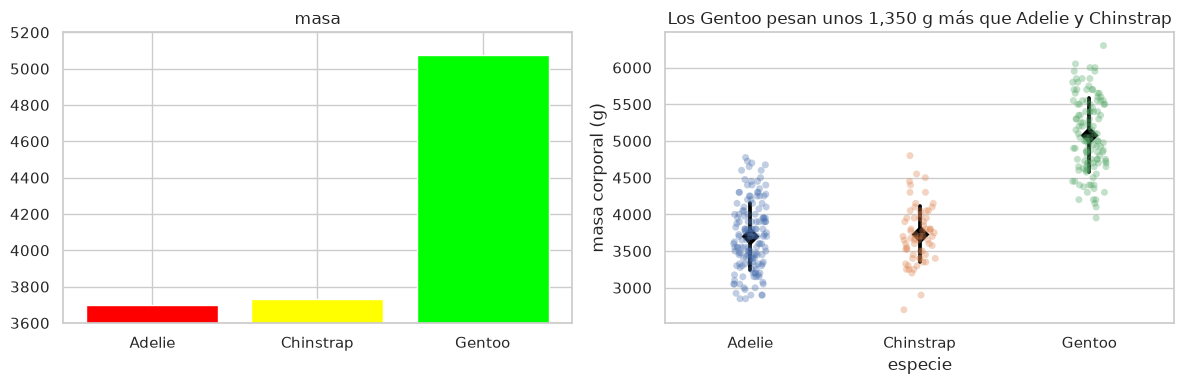

In [4]:
medias_masa = pinguinos.groupby("species")["body_mass_g"].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(medias_masa.index.astype(str), medias_masa, color=["red", "yellow", "lime"])
axes[0].set_ylim(3600, 5200)
axes[0].set_title("masa")

sns.stripplot(pinguinos, x="species", y="body_mass_g", hue="species", alpha=0.35, legend=False, ax=axes[1])
sns.pointplot(pinguinos, x="species", y="body_mass_g", color="black", linestyle="none",
              errorbar="sd", markers="D", ax=axes[1])
axes[1].set(xlabel="especie", ylabel="masa corporal (g)",
            title="Los Gentoo pesan unos 1,350 g más que Adelie y Chinstrap")
plt.tight_layout()
plt.show()

La versión de la izquierda **corta el eje** (las barras parecen indicar que Gentoo pesa varias veces más), usa colores sin significado y no tiene unidades ni título informativo. La de la derecha muestra **todos los datos**, la media con ± una desviación estándar, unidades y un título con el hallazgo.

> 💡 **Matiz sobre el eje en cero:** las **barras** deben empezar en cero porque la altura de la barra representa la cantidad; cortarlas exagera la diferencia. Aquí, la diferencia real entre Gentoo y Adelie es de unos 1,375 g sobre unos 3,700 g, es decir, de 37%; con el eje cortado en 3,600 g, la barra de los Gentoo parece casi 15 veces más alta que la de los Adelie. En una gráfica de **puntos con intervalo** (como la de la derecha) lo que se lee es la posición, no la altura, así que el eje puede no empezar en cero si está bien rotulado.

* La siguiente celda mostrará facetas: la relación aleta–masa por isla, coloreada por especie.

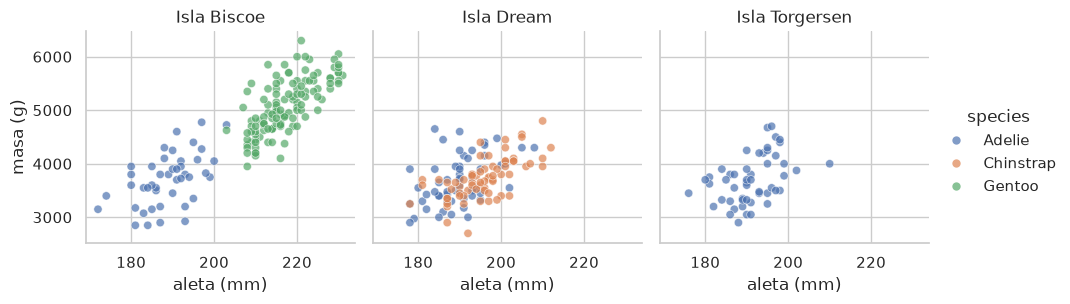

In [5]:
grafica = sns.relplot(pinguinos, x="flipper_length_mm", y="body_mass_g", hue="species", col="island",
                      height=3.2, aspect=1, alpha=0.7)
grafica.set_axis_labels("aleta (mm)", "masa (g)")
grafica.set_titles("Isla {col_name}")
plt.show()

* La siguiente celda agregará una anotación con *Matplotlib* sobre una gráfica de *Seaborn*.

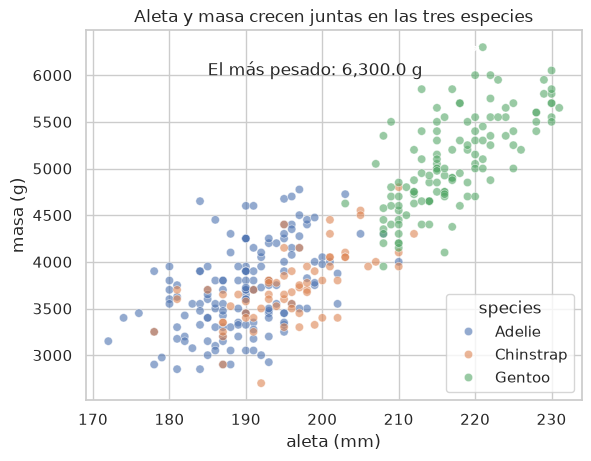

In [6]:
ax = sns.scatterplot(pinguinos, x="flipper_length_mm", y="body_mass_g", hue="species", alpha=0.6)
mas_pesado = pinguinos.loc[pinguinos["body_mass_g"].idxmax()]
ax.annotate(f"El más pesado: {mas_pesado['body_mass_g']:,} g",
            xy=(mas_pesado["flipper_length_mm"], mas_pesado["body_mass_g"]),
            xytext=(185, 6000), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="aleta (mm)", ylabel="masa (g)", title="Aleta y masa crecen juntas en las tres especies")
plt.show()

### Reto 1 · Rescata una gráfica.

**🎯 Objetivo:** rediseñar una gráfica poco efectiva. **Qué se espera aprender:** a aplicar las reglas prácticas de la sección 1.2.

La siguiente celda dibuja una gráfica de pastel de la cantidad de pingüinos por isla y especie. Identifica al menos tres problemas y rehaz la gráfica para responder con claridad "¿qué especies hay en cada isla y cuántas?".

* La siguiente celda dibujará la gráfica de pastel original.

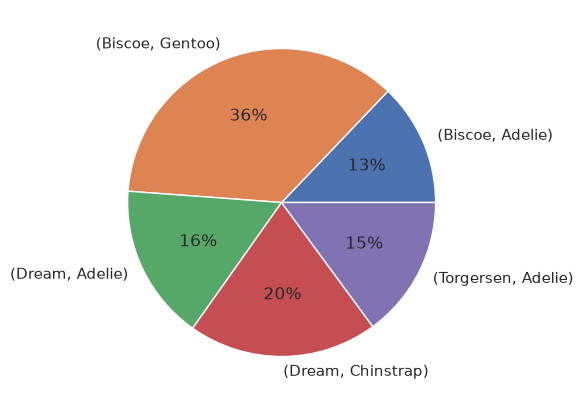

In [7]:
conteos = pinguinos.groupby(["island", "species"]).size()
conteos.plot.pie(figsize=(5, 5), autopct="%.0f%%", ylabel="")
plt.show()

* La siguiente celda muestra una solución posible.

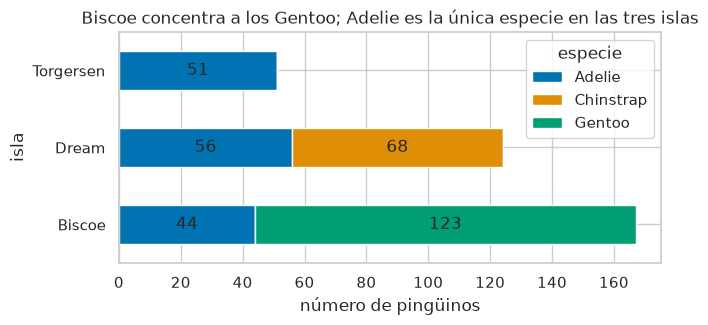

In [8]:
tabla_conteos = pd.crosstab(pinguinos["island"], pinguinos["species"])
ax = tabla_conteos.plot.barh(stacked=True, figsize=(7, 3), color=sns.color_palette("colorblind", 3))
ax.set(xlabel="número de pingüinos", ylabel="isla", title="Biscoe concentra a los Gentoo; Adelie es la única especie en las tres islas")
for contenedor in ax.containers:
    ax.bar_label(contenedor, label_type="center", fmt=lambda v: f"{v:.0f}" if v > 0 else "")
ax.legend(title="especie", bbox_to_anchor=(1, 1))
plt.show()

**✅ Respuesta sugerida:**

Problemas del pastel: (1) las etiquetas combinan isla y especie y son difíciles de leer; (2) los porcentajes son del total y ocultan los conteos; (3) es difícil comparar ángulos y sectores pequeños; (4) no hay título que diga el hallazgo. Unas barras horizontales apiladas con conteos responden directamente la pregunta.

**💡 Ideas clave de la sección 1:**
* La gráfica se elige según la pregunta (distribución, comparación, relación, composición, tiempo).
* Ejes con unidades, título con el hallazgo, color con significado, facetas en lugar de amontonar.
* *Seaborn* para la gráfica estadística; *Matplotlib* para los ajustes finos y las anotaciones.

---
## 2. Ejercicio de la sesión.

### Ejercicio 1 · La gráfica final de la paradoja de Simpson.

**🎯 Objetivo:** producir una gráfica que comunique un hallazgo. **Qué se espera aprender:** a usar color, rectas por grupo y un título que diga la conclusión.

Produce **una sola gráfica** que muestre la paradoja del ejercicio 2 de `14_relaciones_entre_variables.ipynb`: dispersión de `bill_length_mm` vs. `bill_depth_mm` coloreada por especie, una recta por especie, la recta global (por ejemplo, negra y punteada), ejes con unidades, la correlación de cada especie y la global en la leyenda o como anotación, y un título que diga el hallazgo.

* La siguiente celda muestra una solución posible.

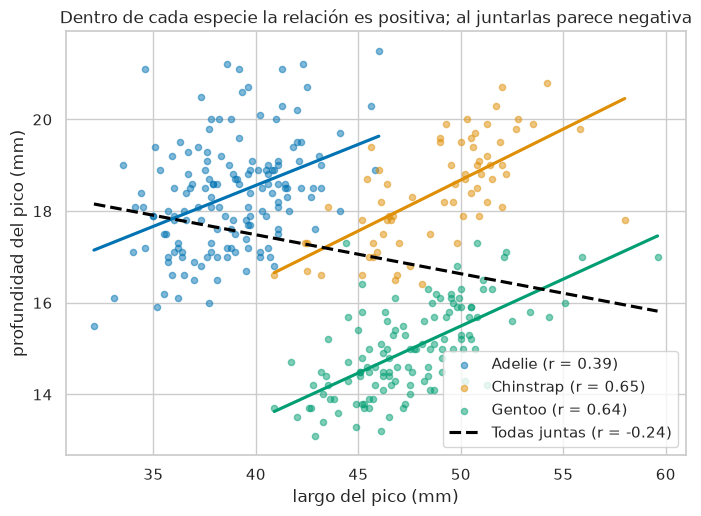

In [9]:
colores = dict(zip(pinguinos["species"].cat.categories, sns.color_palette("colorblind", 3)))
fig, ax = plt.subplots(figsize=(8, 5.5))
for especie, grupo in pinguinos.groupby("species"):
    r = grupo["bill_length_mm"].corr(grupo["bill_depth_mm"])
    sns.regplot(grupo, x="bill_length_mm", y="bill_depth_mm", ci=None, color=colores[especie],
                scatter_kws={"alpha": 0.5, "s": 20}, label=f"{especie} (r = {r:.2f})", ax=ax)
r_todos = pinguinos["bill_length_mm"].corr(pinguinos["bill_depth_mm"])
sns.regplot(pinguinos, x="bill_length_mm", y="bill_depth_mm", ci=None, scatter=False, color="black",
            line_kws={"linestyle": "--"}, label=f"Todas juntas (r = {r_todos:.2f})", ax=ax)
ax.set(xlabel="largo del pico (mm)", ylabel="profundidad del pico (mm)",
       title="Dentro de cada especie la relación es positiva; al juntarlas parece negativa")
ax.legend()
plt.show()

### Ejercicio 2 · Propina porcentual por día y horario.

**🎯 Objetivo:** construir una tabla de doble entrada y revisar el *n* de cada celda. **Qué se espera aprender:** a no comparar medias de celdas con muy pocas observaciones.

1. Construye una tabla de `tip_pct` por `day` (filas) y `time` (columnas) con la **media**, la **mediana** y el **número de cuentas** (pista: `pivot_table(..., aggfunc=["mean", "median", "count"])`).
2. Haz una gráfica que compare `tip_pct` por día y horario mostrando la dispersión, no solo la media.
3. ¿Qué celdas de la tabla están vacías o casi vacías? ¿Qué implica eso para comparar "comida vs. cena"?

* La siguiente celda muestra una solución posible.

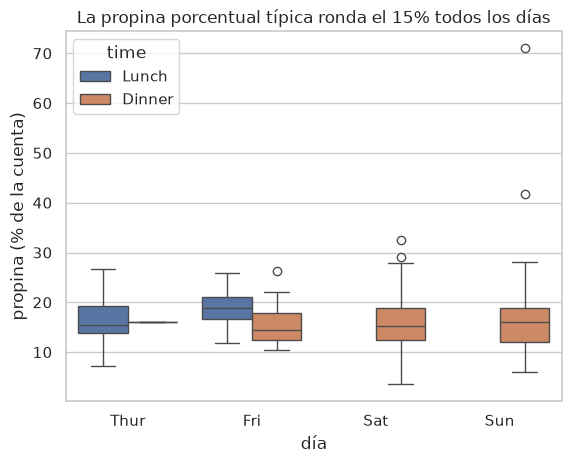

mean        median        count       
time Lunch Dinner  Lunch Dinner Lunch Dinner
day                                         
Thur  16.1   16.0   15.4   16.0  61.0    1.0
Fri   18.9   15.9   18.8   14.5   7.0   12.0
Sat    NaN   15.3    NaN   15.2   NaN   87.0
Sun    NaN   16.7    NaN   16.1   NaN   76.0

In [10]:
tabla_propinas = propinas.pivot_table(index="day", columns="time", values="tip_pct",
                                      aggfunc=["mean", "median", "count"]).round(1)
ax = sns.boxplot(propinas, x="day", y="tip_pct", hue="time")
ax.set(xlabel="día", ylabel="propina (% de la cuenta)",
       title="La propina porcentual típica ronda el 15% todos los días")
plt.show()
tabla_propinas

**✅ Respuesta sugerida:**

La propina porcentual típica ronda 15% a 16% en casi todas las combinaciones; el viernes en comida (media 18.9%) destaca, pero con solo 7 cuentas. La tabla está muy desbalanceada: el sábado y el domingo **no hay comidas**, el jueves hay una sola cena y el viernes solo 19 cuentas en total. Por eso "comida vs. cena" está confundido con el día (las comidas son casi todas de jueves) y cualquier comparación debe reportar el número de cuentas de cada celda.

### Ejercicio 3 · Correlación y causalidad.

**🎯 Objetivo:** identificar explicaciones alternativas de una correlación. **Qué se espera aprender:** a redactar conclusiones sin lenguaje causal injustificado.

Para cada afirmación, indica si es correcta y, si no, cómo la reformularías:
1. "La correlación entre aleta y masa es 0.87, así que las aletas largas hacen que los pingüinos pesen más."
2. "Las mesas que piden en sábado dejan menos propina porcentual porque el sábado la gente es menos generosa."
3. "En el Titanic, viajar en primera clase se **asocia** con una mayor supervivencia; parte de esa asociación podría explicarse por la ubicación de los camarotes y la proporción de mujeres en cada clase."

**✅ Respuesta sugerida:**

1. **Incorrecta.** Es una asociación; ambas medidas reflejan el **tamaño corporal** (y la especie). Mejor: "aleta y masa están fuertemente asociadas (*r* ≈ 0.87); los pingüinos más grandes tienden a tener ambas mayores".
2. **Incorrecta.** La diferencia es pequeña, proviene de un solo mesero y no controla por el tamaño de la mesa, el horario ni el monto. Mejor: "en estos datos, la propina porcentual media del sábado fue algo menor (15.3% contra 16% a 17% otros días)".
3. **Correcta:** usa lenguaje de asociación y menciona posibles confusores.

### Reto 2 · ¿Qué par de medidas separa mejor a las especies?

**🎯 Objetivo:** explorar visualmente todas las relaciones por pares. **Qué se espera aprender:** a usar una matriz de dispersión para elegir variables.

Dibuja `sns.pairplot` de las cuatro medidas coloreado por especie (con KDE en la diagonal). ¿Con qué par de variables se separarían las tres especies casi sin traslape? Justifica con la gráfica.

* La siguiente celda muestra una solución posible.

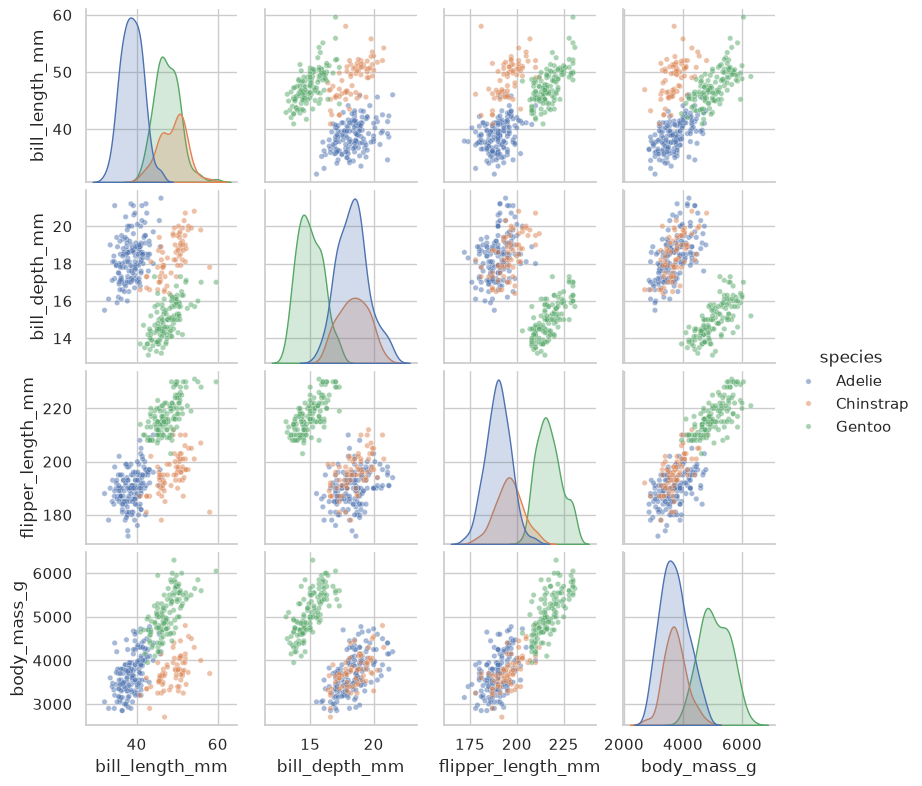

In [11]:
sns.pairplot(pinguinos[medidas + ["species"]], hue="species", diag_kind="kde", height=2,
             plot_kws={"alpha": 0.5, "s": 15})
plt.show()

**✅ Respuesta sugerida:**

Largo del pico contra profundidad del pico (o largo del pico contra aleta) separa las tres especies casi sin traslape: el largo distingue a Adelie (pico corto) de Chinstrap y Gentoo, y la profundidad o la aleta distinguen a Gentoo de Chinstrap. Ninguna variable por sí sola separa las tres especies.

---
## ✅ Cierre.

**Hoy vimos:**
* Agregación con `groupby`/`agg` (agregaciones con nombre), `pivot_table`, `crosstab` y `melt`.
* Correlaciones de Pearson y Spearman, y cuándo difieren.
* Correlación no es causalidad: confusores y la **paradoja de Simpson** en los picos de los pingüinos.
* Visualización efectiva: elegir la gráfica, escalas honestas, facetas, color, rótulos y anotaciones, combinando *Matplotlib* y *Seaborn*.

**Siguiente *notebook*:** `16_distribucion_muestral.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>